In [1]:
import torch

In [463]:
import seaborn as sbn
from numpy import random
import math
import pandas as pd
import matplotlib.pyplot as plt
from torch.nn.functional import one_hot as oneHot

In [3]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [4]:
class Neuron:
    '''
    nin:number of input neruons
    nout:number of output neruons
    '''
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
    # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b] # list append for pprint

class Layer:
    '''
    nin:number of input neruons toward layer
    nout:number of output neruons leaving layer 
    '''
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] # this create input and out put nerons list for a single layer

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
        # return outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    '''
    nin: number of input neruons entering the first layer or input of the model
    nouts: list which contain number of output neurons for each layer, len(nouts) indicate number of layers, nout_i indicates number of output neurons for layer_i,
    loop takes care of previous output is input for next
    '''
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [5]:
with open('./bigramsData/names.txt','r') as f:
    words=[i.strip() for i in f.readlines()]

Trying to understand local str, what letters comes after what letters one character after what

In [6]:
def getStats(x:list):
    x=[len(i) for i in x]
    return "Min Word size %d, Max word Size %d" % (min(x),max(x))

In [7]:
words

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn',
 'abigail',
 'emily',
 'elizabeth',
 'mila',
 'ella',
 'avery',
 'sofia',
 'camila',
 'aria',
 'scarlett',
 'victoria',
 'madison',
 'luna',
 'grace',
 'chloe',
 'penelope',
 'layla',
 'riley',
 'zoey',
 'nora',
 'lily',
 'eleanor',
 'hannah',
 'lillian',
 'addison',
 'aubrey',
 'ellie',
 'stella',
 'natalie',
 'zoe',
 'leah',
 'hazel',
 'violet',
 'aurora',
 'savannah',
 'audrey',
 'brooklyn',
 'bella',
 'claire',
 'skylar',
 'lucy',
 'paisley',
 'everly',
 'anna',
 'caroline',
 'nova',
 'genesis',
 'emilia',
 'kennedy',
 'samantha',
 'maya',
 'willow',
 'kinsley',
 'naomi',
 'aaliyah',
 'elena',
 'sarah',
 'ariana',
 'allison',
 'gabriella',
 'alice',
 'madelyn',
 'cora',
 'ruby',
 'eva',
 'serenity',
 'autumn',
 'adeline',
 'hailey',
 'gianna',
 'valentina',
 'isla',
 'eliana',
 'quinn',
 'nevaeh',
 'ivy',
 'sadie',
 'piper',
 'lydia',
 'alexa',
 'josephine',
 'emery',
 'julia'

In [8]:
print(getStats(words))

Min Word size 2, Max word Size 15


In [9]:
for w in words[:3]:
    for ch1,ch2 in zip(w,w[1:]):
        print(ch1,ch2)

e m
m m
m a
o l
l i
i v
v i
i a
a v
v a


In [10]:
with open('tinyShakepears.txt','r') as f:
    chars=list(set(f.read().strip()))
    chars.sort()

In [11]:
''.join(chars)

"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

In [12]:
ID2char_DictMap={_id_:char for _id_,char in enumerate(chars)}
char2ID_DictMap={char:_id_ for _id_,char in ID2char_DictMap.items()}
encoder=lambda X:[char2ID_DictMap.get(x,-1) for x in X]
decoder=lambda X:''.join([ID2char_DictMap.get(x,-1) for x in X])
spaceCharacter=char2ID_DictMap.get(' ')
maxSize=15

In [60]:
spaceCharacter

1

In [14]:
encoder(words[0])

[43, 51, 51, 39]

In [15]:
decoder(encoder(words[0]))

'emma'

In [282]:
proabilityDict={}
for _w in words:
    word='?'+_w+' '
    _=encoder(word)
    for _,_2 in zip(_,_[1:]):
        if _ in proabilityDict.keys():
            if _2 in proabilityDict[_].keys():
                proabilityDict[_][_2]+=1
            else:
                proabilityDict[_][_2]=1
        else:
            proabilityDict[_]={_2:1}

allKeys=list(proabilityDict.keys())+encoder(' ')

for key,value in proabilityDict.items():
    x=sum(value.values())
    _={}
    for checkKey in allKeys:
        val2=value.get(checkKey,0)
        _[checkKey]=val2/x
    proabilityDict[key]=_
proabilityDict[spaceCharacter]={}
for checkKey in allKeys:
    proabilityDict[1][checkKey]=0.0


In [138]:
encoder(word)

[12, 64, 64, 63, 64, 62, 1]

<Axes: ylabel='Density'>

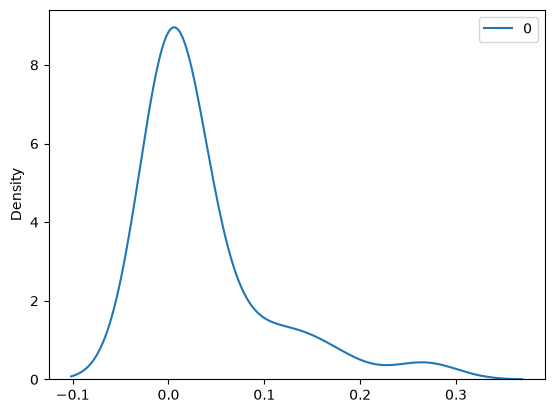

In [139]:
sbn.kdeplot(proabilityDict[44].values())

In [150]:
model=MLP(1,[4,4,4,28])

In [237]:
X=list(proabilityDict.keys())
stepSize=0.001
records=[]
for _iter_ in range(100):
    for x in X:
        ys=list(proabilityDict[x].values())
        yPred=model([x])
        loss_each=[(yout-ygt)**2 for ygt,yout in zip(ys,yPred)]
        loss=sum(loss_each)

        for p in model.parameters():
            p.grad=0
        
        loss.backward()
        # update
        for p in model.parameters():
            p.data+=stepSize*(-1*p.grad)
    records.append([_iter_,loss.data])


<Axes: ylabel='Count'>

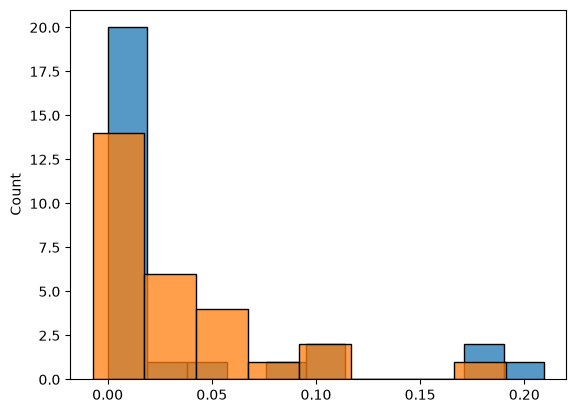

In [238]:
val=[i.data for i in model([50])]
sbn.histplot(proabilityDict[50])
sbn.histplot(val)

In [239]:
import numpy as np

keys = list(allKeys)   # output i of the model corresponds to keys[i]

def sample_next(x):
    out = model([x])
    p = np.array([o.data for o in out])           # plain floats
    p = np.clip(p, 0, None)                       # no negative probabilities
    if p.sum() == 0:
        p = np.ones_like(p)                       # fallback: uniform
    p = p / p.sum()                               # must sum to 1
    return keys[np.random.choice(len(keys), p=p)]

def generate(start_char, max_len=15):
    idx = char2ID_DictMap[start_char]
    out = [idx]
    for _ in range(max_len):
        idx = sample_next(idx)
        if idx!=encoder('?')[0]:
            out.append(idx) 
        if idx == spaceCharacter:
            break
    return decoder(out[:-1])

In [240]:
len(allKeys)

28

In [241]:
encoder('e')

[43]

In [242]:
decoder([43])

'e'

In [281]:
generate('c')

'cniirne'

In [47]:
pd.DataFrame(records,columns=['Iter','Loss'])

,Iter,Loss
0,0,8.924867
1,1,6.712602
2,2,5.462198
3,3,4.931908
4,4,4.586723
...,...,...
95,95,0.120671
96,96,0.120610
97,97,0.120553
98,98,0.120501


Now lets try it with torch

In [376]:
N = torch.zeros((27, 27), dtype=torch.float32)

In [377]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i,s in enumerate(chars,1)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [378]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1

(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

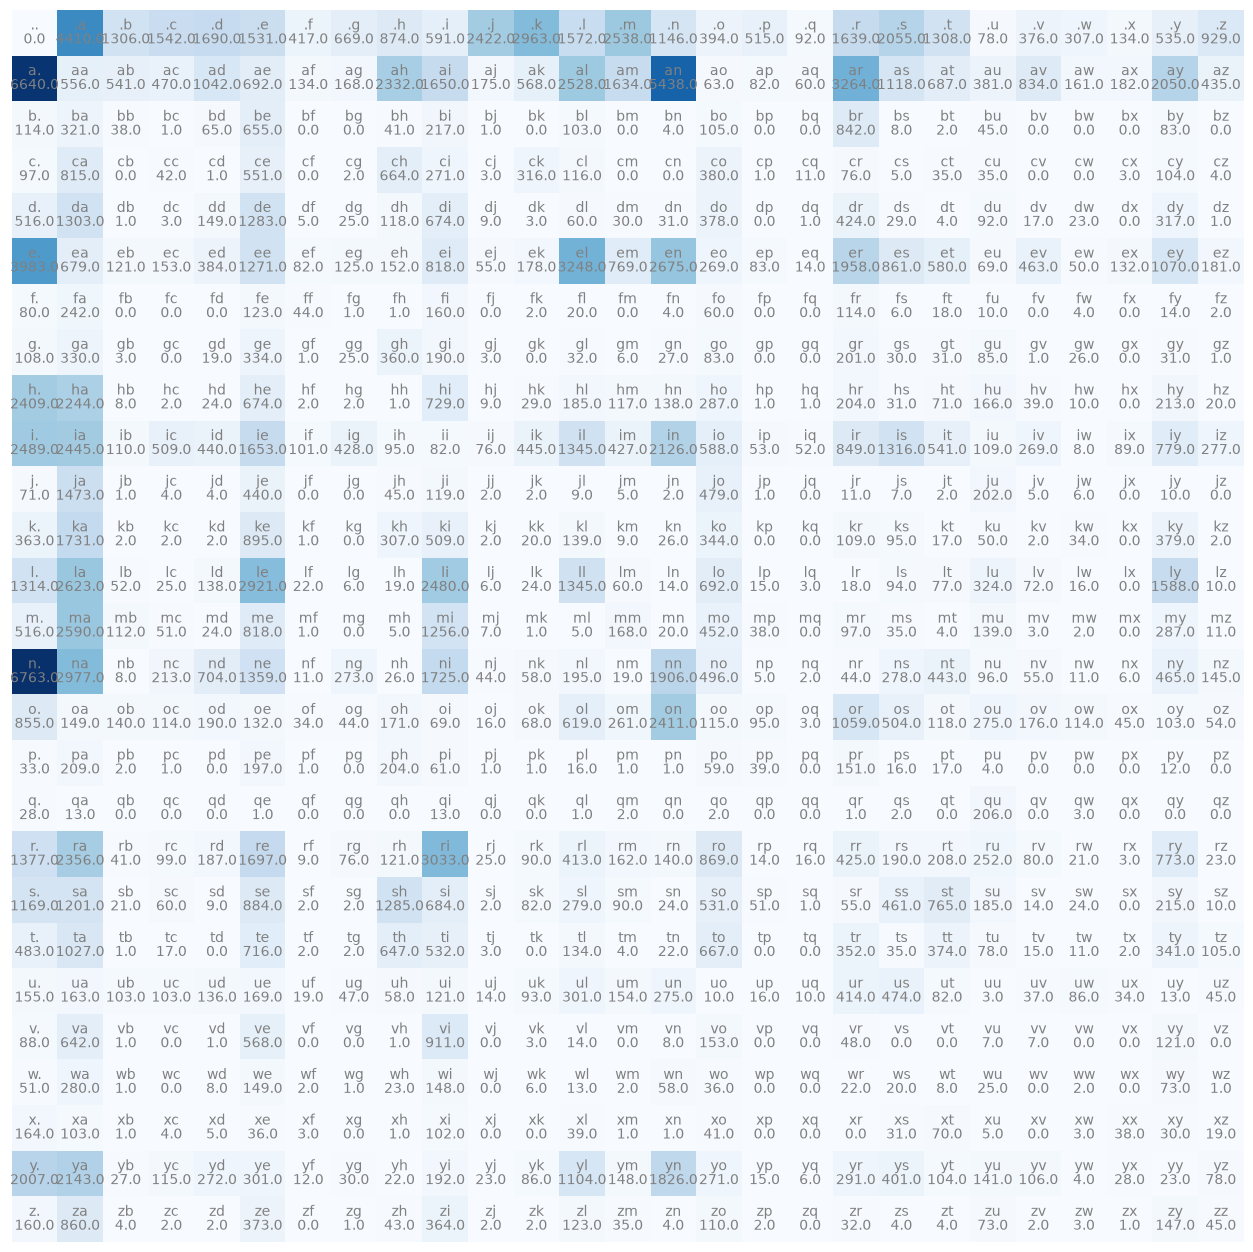

In [379]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off')

## Simple count proabiltiy log lik model is used to compare neural network

In [444]:
P=N.detach().clone()
# for i in range(P.shape[0]):
    # P[i,:]=P[i,:]/(P[i,:].sum())
P=P/P.sum(1,keepdim=True)
# for i in 
# N[0,:]/N[0,:]

In [445]:
idx=0
names=[]
for i in range(20):
    out=[]
    while True:
        p=P[idx,:]
        idx=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
        if idx==0:
            break
        out.append(itos[idx])
    names.append(''.join(out))
print('\n'.join(names))

lzio
briliy
feshrlinallelen
h
a
irkonttrlin
chanasirn
angopamykecora
reristik
indmra
gon
en
eron
myiobelinn
is
ne
lio
h
penan
h


In [446]:
negLogLik=0
n=0
for w in words:
    chs=['.']+list(w)+['.']
    for w1,w2 in zip(chs,chs[1:]):
        ix1,ix2=stoi[w1],stoi[w2]
        prob=P[ix1,ix2]
        negLog=-1* torch.log(prob)
        negLogLik+=negLog
        n+=1
negLogLik/n

tensor(2.4541)

* avg - log likey is used as loss function as lower the better
* in our N matrix we can add +1 or any number to smooth the matrix basically remove zero entry which can cause trouble

In [447]:
P=N.detach().clone()
P=P+1
# for i in range(P.shape[0]):
    # P[i,:]=P[i,:]/(P[i,:].sum())
P=P/P.sum(1,keepdim=True)
# for i in 
# N[0,:]/N[0,:]

In [448]:
idx=0
names=[]
for i in range(20):
    out=[]
    while True:
        p=P[idx,:]
        idx=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
        if idx==0:
            break
        out.append(itos[idx])
    names.append(''.join(out))
print('\n'.join(names))

kqwanelenid
mbeayanna
i
ore
kavie
kwyannar
r
xsaudo
kalad
tanniochan
damama
erolwe
josut
ayntrei
s
rinilealonsh
ex
daeee
ah
ah


In [502]:
negLogLik=0
n=0
for w in words:
    chs=['.']+list(w)+['.']
    for w1,w2 in zip(chs,chs[1:]):
        ix1,ix2=stoi[w1],stoi[w2]
        prob=P[ix1,ix2]
        negLog=-1* torch.log(prob)
        negLogLik+=negLog
        n+=1
negLogLik/n

tensor(2.4544)

* Now the real modeling of MLP

In [578]:
# training Set of bigrams (x,y)

xs,ys=[],[]

n=int(0.9*len(words))
for w in words[:n]:
    chs=['.']+list(w)+['.']
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1=stoi[ch1]
        ix2=stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs=torch.tensor(xs)
ys=torch.tensor(ys)

In [579]:
xs

tensor([ 0,  5, 13,  ...,  1,  1, 13])

In [580]:
ys

tensor([ 5, 13, 13,  ...,  1, 13,  0])

Rather than integer in neuoral net, we make those int as vector or binary like in case of this 26,1 vector with each position telling what letter it is like 13 become 00000001000 something like this

In [581]:
xencod=oneHot(xs,num_classes=27).float()
yencod=oneHot(ys,num_classes=27).float()

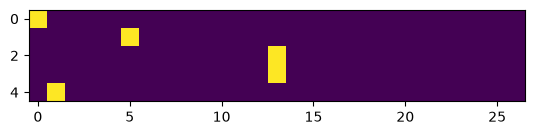

In [582]:
plt.imshow(xencod[0:5,])

## Forward pass

3,13 means firing rate of 3rd input on 13 neuron

* (27, 1): 1 neuron that takes 27 inputs. It has 27 weights, one per input. For a batch of N inputs, x @ W has shape (N, 27) @ (27, 1) = (N, 1), so each sample gets one output number.

* (27, 27): 27 neurons, each taking the same 27 inputs. That’s 27 × 27 = 729 weights. x @ W has shape (N, 27) @ (27, 27) = (N, 27), so each sample gets 27 output numbers.

(xencod @ W) [3,13] = (xencod[3] dot product W[:,13]).sum()


Calculating of forward pass is most imp the genrator and transformer are just extention of this, how we calculate logits

In [637]:
# X*W +b matrix mul 

# this is  forward pass
W=torch.randn(size=(27,27),requires_grad=True) # first 27 is for the classes of X i.e for each type of input XiWi the second 27 is number of neurons so there are 27 neurons 
# W=torch.zeros(size=(27,27),requires_grad=True) # first 27 is for the classes of X i.e for each type of input XiWi the second 27 is number of neurons so there are 27 neurons 
t=xencod@W #logit
probs=(t.exp()/t.exp().sum(axis=1,keepdim=True)) #softmax

In [638]:
xencod.shape

torch.Size([205411, 27])

In [639]:
probs.shape

torch.Size([205411, 27])

In [640]:
xs

tensor([ 0,  5, 13,  ...,  1,  1, 13])

In [641]:
ys

tensor([ 5, 13, 13,  ...,  1, 13,  0])

In [642]:
nlls = torch.zeros(5)
for i in range(5):
  # i-th bigram:
  x = xs[i].item() # input character index
  y = ys[i].item() # label character index
  print('--------')
  print(f'bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y})')
  print('input to the neural net:', x)
  print('output probabilities from the neural net:', probs[i])
  print('label (actual next character):', y)
  p = probs[i, y]
  print('probability assigned by the net to the the correct character:', p.item())
  logp = torch.log(p)
  print('log likelihood:', logp.item())
  nll = -logp
  print('negative log likelihood:', nll.item())
  nlls[i] = nll

print('=========')
print('average negative log likelihood, i.e. loss =', nlls.mean().item())

--------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0645, 0.0173, 0.0242, 0.0218, 0.1095, 0.0083, 0.0140, 0.0345, 0.0200,
        0.0100, 0.0107, 0.0156, 0.0246, 0.0403, 0.0197, 0.0924, 0.0042, 0.0584,
        0.0695, 0.0085, 0.0227, 0.0137, 0.0808, 0.0331, 0.0282, 0.1352, 0.0183],
       grad_fn=<SelectBackward0>)
label (actual next character): 5
probability assigned by the net to the the correct character: 0.00834906380623579
log likelihood: -4.7856059074401855
negative log likelihood: 4.7856059074401855
--------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.1142, 0.0077, 0.0334, 0.1897, 0.0130, 0.0159, 0.0333, 0.0290, 0.0052,
        0.0187, 0.0574, 0.0160, 0.0101, 0.0857, 0.0126, 0.0706, 0.0321, 0.0177,
        0.0072, 0.0548, 0.0129, 0.0182, 0.0415, 0.0296, 0.0144, 0.0225, 0.0365],
       grad_fn=<SelectBackward0>)
label (actual next character

In [643]:
'''
to compare ys and ypred, we can use _=probs[torch.arange(sizeofInput),ys)] this will gives us ypred directley rather than iterating over things
for log lik we can just -1*_.log().mean()
'''

ypred=probs[torch.arange(xencod.shape[0]),ys]
loss=-ypred.log().mean()
loss

tensor(3.7386, grad_fn=<NegBackward0>)

In [644]:
ypred

tensor([0.0083, 0.0857, 0.0013,  ..., 0.0204, 0.0076, 0.0750],
       grad_fn=<IndexBackward0>)

## backward pass

In [645]:
W.grad=None
loss.backward()


In [647]:
for _iter_ in range(100):
    logit=xencod@W
    count=logit.exp()
    probs=(count/count.sum(axis=1,keepdim=True)) #softmax
    ypred=probs[torch.arange(xencod.shape[0]),ys]
    loss=-ypred.log().mean()+ 0.01* (W**2).mean()
    W.grad=None
    loss.backward()
    W.data+=stepSize*(-1*W.grad)


+ 0.01* (W**2).mean() is added so that those W which are big are penilized 

In [648]:
ypred.log()

tensor([-3.0260, -3.2988, -3.7236,  ..., -4.1475, -3.0417, -2.6581],
       grad_fn=<LogBackward0>)

In [627]:
stepSize=50

In [634]:
t=xencod@W
probs=(t.exp()/t.exp().sum(axis=1,keepdim=True)) #softmax
ypred=probs[torch.arange(xencod.shape[0]),ys]
loss=-ypred.log().mean()
loss

tensor(2.4514, grad_fn=<NegBackward0>)

tensor([ 5, 13, 13,  ...,  1, 13,  0])

In [649]:
ypred

tensor([0.0485, 0.0369, 0.0241,  ..., 0.0158, 0.0478, 0.0701],
       grad_fn=<IndexBackward0>)

In [701]:
# finally, sample from the 'neural net' model
# g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = oneHot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

ka.
emia.
sade.
enkaviyny.
ftlsp.


In [676]:
len(p[0])

27

In [696]:
p

tensor([[0.2090, 0.0158, 0.0156, 0.0134, 0.0306, 0.0200, 0.0040, 0.0053, 0.0698,
         0.0474, 0.0049, 0.0162, 0.0760, 0.0478, 0.1565, 0.0021, 0.0027, 0.0019,
         0.0943, 0.0310, 0.0202, 0.0107, 0.0230, 0.0045, 0.0051, 0.0599, 0.0123]],
       grad_fn=<DivBackward0>)